# Half-hour detection totals — 1 September 2026

Compare **s1: highschool_13 NW**, **s2: corbins_12 NW**, and **s3: frantz_9 NW** using the same data and approach filters as the ECDF notebooks. Here each comparison uses only the **total count in a half-hour**, not a distribution or an ECDF distance.

The default counts rows, including repeated request updates. Change `COUNT_MODE` to `"first_seen_requests"` to count each request ID once per camera within this file. Neither represents verified completed crossings.

Align to the middle camera: s1 +30 seconds, s2 unchanged, s3 −30 seconds. Only common supported time is counted. Consequently, the first and last windows contain 29 minutes 30 seconds of coverage; the other windows contain 30 minutes. Missing boundary data is not treated as zero. Timestamps retain the stored clock.

Flags are camera/window anomaly candidates, not proven faults. A count difference may reflect traffic turning, different reporting rates, or a wrong travel-time assumption. Equal totals can hide timing and distribution anomalies. All-silent windows are shown separately; without heartbeats, zero cannot distinguish no traffic from missing reporting.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DAY = "2026-09-01"
COUNT_MODE = "rows"  # Or "first_seen_requests" to remove repeated request updates.
BIN = "30s"
WINDOW = "30min"
TRAVEL_SECONDS = 30

# Editable candidate-flag thresholds (not calibrated against labeled faults).
SCORE_THRESHOLD = 0.30
REFERENCE_GAP_MAX = 0.20  # Maximum symmetric relative gap between the other two totals.

# Works when launched from the notebook folder or the mobility workspace.
DATA_FILE = next(
    (folder / f"{DAY}.parquet" for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / f"{DAY}.parquet").is_file()),
    None,
)
if DATA_FILE is None:
    raise FileNotFoundError(f"Set DATA_FILE to the location of {DAY}.parquet")

cameras = pd.DataFrame([
    ["s1", "bridge.highschool_13", "SENSOR-bridge.highschool_13-fc_du_bridge.highschool_nw", "23.13", TRAVEL_SECONDS],
    ["s2", "bridge.corbins_12", "SENSOR-bridge.corbins_12-fc_du_bridge.corbins_nw", "13.12", 0],
    ["s3", "bridge.frantz_9", "SENSOR-bridge.frantz_9-fc_du_bridge.frantz_nw", "12.9", -TRAVEL_SECONDS],
], columns=["camera", "intersection", "sensor_id", "incoming_link", "shift_seconds"])
display(cameras)
print("Reading:", DATA_FILE)

,camera,intersection,sensor_id,incoming_link,shift_seconds
0,s1,bridge.highschool_13,SENSOR-bridge.highschool_13-fc_du_bridge.highs...,23.13,30
1,s2,bridge.corbins_12,SENSOR-bridge.corbins_12-fc_du_bridge.corbins_nw,13.12,0
2,s3,bridge.frantz_9,SENSOR-bridge.frantz_9-fc_du_bridge.frantz_nw,12.9,-30


Reading: /home/michal/mobility/2026-09-01.parquet


## Select the cameras and approaches

Strip the changing object/counter suffix from `sourceId`, preserving the location and NW direction. Require both the camera's own intersection and the specified incoming link, so forwarded records at other junctions and other approaches do not inflate the comparison. `REMOTE_SENSOR`, `NTCIP_CALL`, and `STARVATION` records are excluded. The audit shows records removed by the approach filter.

In [2]:
raw = pd.read_parquet(
    DATA_FILE,
    columns=["timestamp", "intersection_id", "source", "sourceId", "incomingLink_id", "id"],
    filters=[("intersection_id", "in", cameras["intersection"].tolist()), ("source", "==", "SENSOR")],
)
raw["timestamp"] = pd.to_datetime(raw["timestamp"])
raw["sensor_id"] = raw["sourceId"].str.replace(
    r"^(SENSOR-.*_(?:ne|nw|se|sw|n|e|s|w))\d+.*$", r"\1", regex=True
)
start = pd.Timestamp(DAY)
end = start + pd.Timedelta(days=1)
raw = raw[(raw["timestamp"] >= start) & (raw["timestamp"] < end)]

streams = {}
audit_rows = []
if COUNT_MODE not in ["rows", "first_seen_requests"]:
    raise ValueError("COUNT_MODE must be rows or first_seen_requests")
for camera in cameras.itertuples(index=False):
    selected = raw[(raw["intersection_id"] == camera.intersection)
                   & (raw["sensor_id"] == camera.sensor_id)].copy()
    approach = selected[selected["incomingLink_id"] == camera.incoming_link].sort_values("timestamp")
    events = approach.copy()
    if COUNT_MODE == "first_seen_requests":
        events = events.dropna(subset=["id"]).drop_duplicates("id", keep="first")
    streams[camera.camera] = events
    audit_rows.append({
        "camera": camera.camera, "camera_rows": len(selected),
        "excluded_other_links": len(selected) - len(approach),
        "selected_rows": len(approach), "distinct_request_ids": approach["id"].nunique(),
        "missing_request_ids": approach["id"].isna().sum(),
        "counted_events": len(events), "first_record": approach["timestamp"].min(),
        "last_record": approach["timestamp"].max(),
    })
audit = pd.DataFrame(audit_rows).set_index("camera")
display(audit)
if (audit["counted_events"] == 0).any():
    print("Warning: at least one selected camera has no records; check selection and data availability.")

,camera_rows,excluded_other_links,selected_rows,distinct_request_ids,missing_request_ids,counted_events,first_record,last_record
camera,,,,,,,,
s1,19814,4,19810,15872,0,19810,2026-09-01 00:00:00.101,2026-09-01 23:59:53.894
s2,21950,108,21842,17520,0,21842,2026-09-01 00:00:04.762,2026-09-01 23:59:57.627
s3,30804,133,30671,18136,0,30671,2026-09-01 00:00:03.903,2026-09-01 23:59:56.882


## Align the count streams

For example, s1 at 12:00:00, s2 at 12:00:30, and s3 at 12:01:00 all align to 12:00:30. Empty bins inside the file's nominal day count as zero; without sensor heartbeat data, zero cannot distinguish no traffic from missing reporting. The first and last half-hours have 59 common bins; interior windows have 60.

The 30-second grid below is used only to align coverage. The actual anomaly comparison uses the summed half-hour totals.

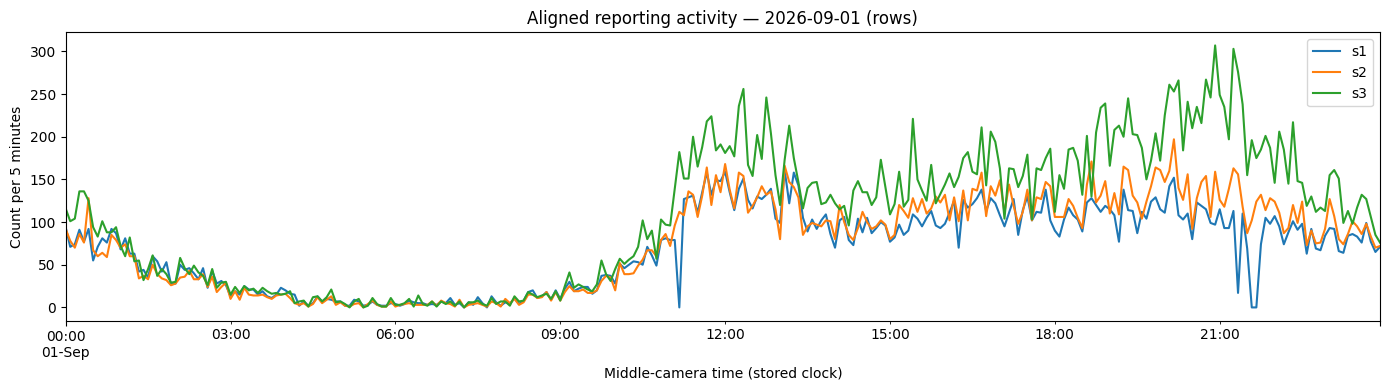

In [3]:
bin_width = pd.Timedelta(BIN)
grid = pd.date_range(start, end, freq=BIN, inclusive="left")
aligned = pd.DataFrame(index=grid)
for camera in cameras.itertuples(index=False):
    shift = pd.Timedelta(seconds=camera.shift_seconds)
    times = streams[camera.camera]["timestamp"] + shift
    counts = times.dt.floor(BIN).value_counts().reindex(grid, fill_value=0).sort_index()
    # A complete bin must fall within the shifted source day's coverage.
    available = (grid >= start + shift) & (grid + bin_width <= end + shift)
    aligned[camera.camera] = counts.astype(float).where(available)
aligned.index.name = "middle_camera_time"

aligned.resample("5min").sum(min_count=1).plot(figsize=(14, 4))
plt.title(f"Aligned reporting activity — {DAY} ({COUNT_MODE})")
plt.xlabel("Middle-camera time (stored clock)")
plt.ylabel("Count per 5 minutes")
plt.tight_layout()
plt.show()

## Compare totals for every half-hour

The table includes the three totals and their absolute pairwise differences. For flagging, use the symmetric relative count gap:

`gap(a, b) = 2 * abs(a - b) / (a + b)`; the gap is 0 when both totals are zero.

The gap ranges from 0 (equal totals) to 2 (only one total is zero). For example, totals 100 and 120 give 20 / 110 ≈ 0.182. This is relative to the pair's average, not to one sensor.

For camera i with reference cameras j and k:

`score_i = max(0, min(gap(i,j), gap(i,k)) - gap(j,k))`

Flag i when its score is at least `SCORE_THRESHOLD` and the reference gap is at most `REFERENCE_GAP_MAX`. Defaults 0.30 and 0.20 are editable exploratory values, not calibrated fault thresholds. The score is not a probability. Small counts can produce large relative differences, so inspect the totals alongside flags.

In [4]:
def relative_gap(a, b):
    return 0.0 if a + b == 0 else 2 * abs(a - b) / (a + b)


def score_and_flag(d1, d2, reference_gap):
    score = max(0.0, min(d1, d2) - reference_gap)
    return score, score >= SCORE_THRESHOLD and reference_gap <= REFERENCE_GAP_MAX


assert 0 < SCORE_THRESHOLD <= 2
assert 0 <= REFERENCE_GAP_MAX <= 2
sensors = ["s1", "s2", "s3"]
window_rows, sensor_rows = [], []
for window_start in pd.date_range(start, end, freq=WINDOW, inclusive="left"):
    window_end = window_start + pd.Timedelta(WINDOW)
    common = aligned.loc[(aligned.index >= window_start) & (aligned.index < window_end)].dropna()
    totals = common.sum() if len(common) else pd.Series(np.nan, index=sensors)
    row = {"window_start": window_start, "window_end": window_end,
           "coverage_minutes": len(common) * pd.Timedelta(BIN).total_seconds() / 60}
    gaps = {}
    for a, b in [("s1", "s2"), ("s1", "s3"), ("s2", "s3")]:
        gaps[(a, b)] = relative_gap(totals[a], totals[b]) if len(common) else np.nan
        row[f"gap_{a}_{b}"] = gaps[(a, b)]
        row[f"absolute_difference_{a}_{b}"] = abs(totals[a] - totals[b])
    flagged = []
    for sensor in sensors:
        others = [s for s in sensors if s != sensor]
        d1 = gaps[tuple(sorted([sensor, others[0]]))]
        d2 = gaps[tuple(sorted([sensor, others[1]]))]
        reference_gap = gaps[tuple(sorted(others))]
        score, flag = score_and_flag(d1, d2, reference_gap) if len(common) else (np.nan, False)
        reference_total = totals[others].mean()
        row[f"{sensor}_total"] = totals[sensor]
        row[f"{sensor}_score"] = score
        row[f"{sensor}_flag"] = flag
        if flag:
            flagged.append(sensor)
        sensor_rows.append({
            "window_start": window_start, "window_end": window_end, "sensor": sensor,
            "coverage_minutes": row["coverage_minutes"], "total": totals[sensor],
            "reference_mean_total": reference_total,
            "count_difference": totals[sensor] - reference_total,
            "ratio_to_reference": totals[sensor] / reference_total if reference_total > 0 else np.nan,
            "reference_gap": reference_gap, "score": score, "flag": flag,
        })
    row["flagged_sensors"] = ", ".join(flagged) if flagged else "none"
    row["status"] = ("no_common_coverage" if common.empty else "all_silent" if totals.sum() == 0
                     else "candidate_anomaly" if flagged
                     else "inconclusive_no_pair_agrees" if min(gaps.values()) > REFERENCE_GAP_MAX
                     else "no_flag")
    window_rows.append(row)
metrics = pd.DataFrame(window_rows)
sensor_metrics = pd.DataFrame(sensor_rows)
with pd.option_context("display.max_rows", 48, "display.max_columns", None):
    display(metrics.round(3))
display(sensor_metrics.groupby("sensor")["flag"].sum().rename("flagged_windows").to_frame())

,window_start,window_end,coverage_minutes,gap_s1_s2,absolute_difference_s1_s2,gap_s1_s3,absolute_difference_s1_s3,gap_s2_s3,absolute_difference_s2_s3,s1_total,s1_score,s1_flag,s2_total,s2_score,s2_flag,s3_total,s3_score,s3_flag,flagged_sensors,status
0,2026-09-01 00:00:00,2026-09-01 00:30:00,29.5,0.039,20.0,0.339,204.0,0.301,184.0,499.0,0.000,False,519.0,0.000,False,703.0,0.262,False,none,no_flag
1,2026-09-01 00:30:00,2026-09-01 01:00:00,30.0,0.110,48.0,0.170,86.0,0.279,134.0,462.0,0.000,False,414.0,0.000,False,548.0,0.061,False,none,no_flag
2,2026-09-01 01:00:00,2026-09-01 01:30:00,30.0,0.075,26.0,0.017,6.0,0.058,20.0,361.0,0.000,False,335.0,0.041,False,355.0,0.000,False,none,no_flag
3,2026-09-01 01:30:00,2026-09-01 02:00:00,30.0,0.235,57.0,0.057,15.0,0.179,42.0,271.0,0.000,False,214.0,0.122,False,256.0,0.000,False,none,no_flag
4,2026-09-01 02:00:00,2026-09-01 02:30:00,30.0,0.147,33.0,0.087,22.0,0.234,55.0,241.0,0.000,False,208.0,0.060,False,263.0,0.000,False,none,no_flag
5,2026-09-01 02:30:00,2026-09-01 03:00:00,30.0,0.147,27.0,0.036,7.0,0.111,20.0,197.0,0.000,False,170.0,0.075,False,190.0,0.000,False,none,no_flag
6,2026-09-01 03:00:00,2026-09-01 03:30:00,30.0,0.235,24.0,0.076,9.0,0.310,33.0,114.0,0.000,False,90.0,0.159,False,123.0,0.000,False,none,no_flag
7,2026-09-01 03:30:00,2026-09-01 04:00:00,30.0,0.182,16.0,0.108,11.0,0.289,27.0,96.0,0.000,False,80.0,0.073,False,107.0,0.000,False,none,no_flag
8,2026-09-01 04:00:00,2026-09-01 04:30:00,30.0,0.408,21.0,0.102,6.0,0.309,15.0,62.0,0.000,False,41.0,0.208,False,56.0,0.000,False,none,no_flag
9,2026-09-01 04:30:00,2026-09-01 05:00:00,30.0,0.103,5.0,0.328,20.0,0.427,25.0,51.0,0.000,False,46.0,0.000,False,71.0,0.225,False,none,no_flag


,flagged_windows
sensor,
s1,0
s2,2
s3,5


## Total detections through the day

Each point is one half-hour total. Red crosses mark flagged sensor/window pairs.

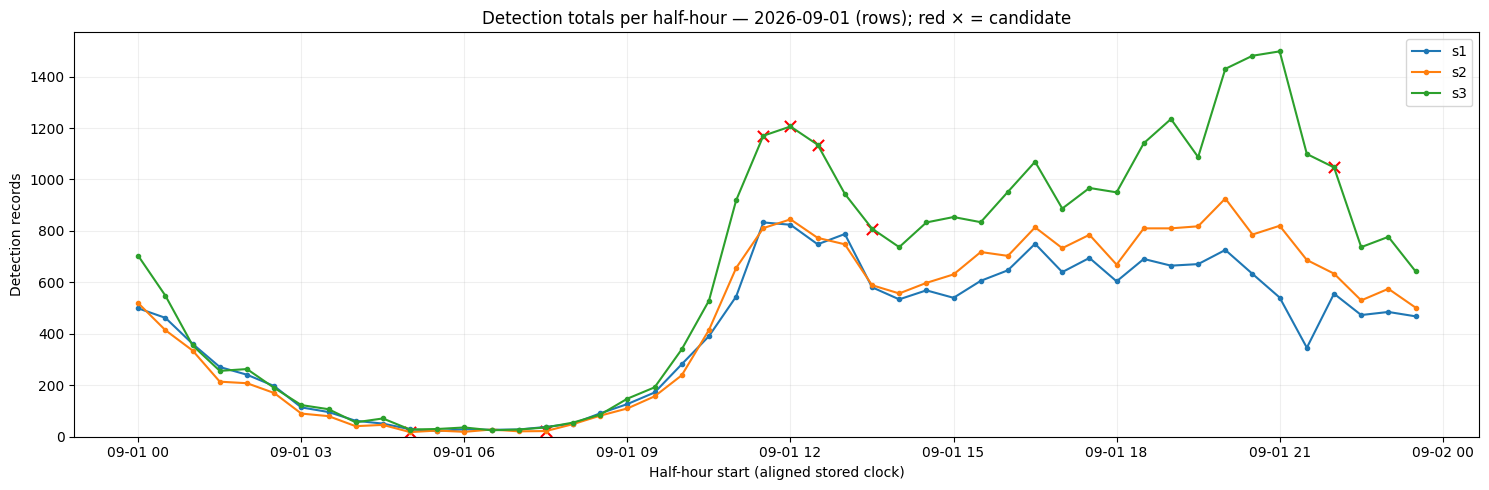

In [5]:
colors = {"s1": "tab:blue", "s2": "tab:orange", "s3": "tab:green"}
fig, ax = plt.subplots(figsize=(15, 5))
for sensor in sensors:
    ax.plot(metrics["window_start"], metrics[f"{sensor}_total"], marker=".", color=colors[sensor], label=sensor)
    flagged = metrics[metrics[f"{sensor}_flag"]]
    ax.scatter(flagged["window_start"], flagged[f"{sensor}_total"], color="red", marker="x", s=65)
ax.set_title(f"Detection totals per half-hour — {DAY} ({COUNT_MODE}); red × = candidate")
ax.set_xlabel("Half-hour start (aligned stored clock)")
ax.set_ylabel("Detection records")
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Side-by-side totals in every window

These bars replace the ECDF overlays. Each figure covers six hours. Red outlines mark candidate flags.

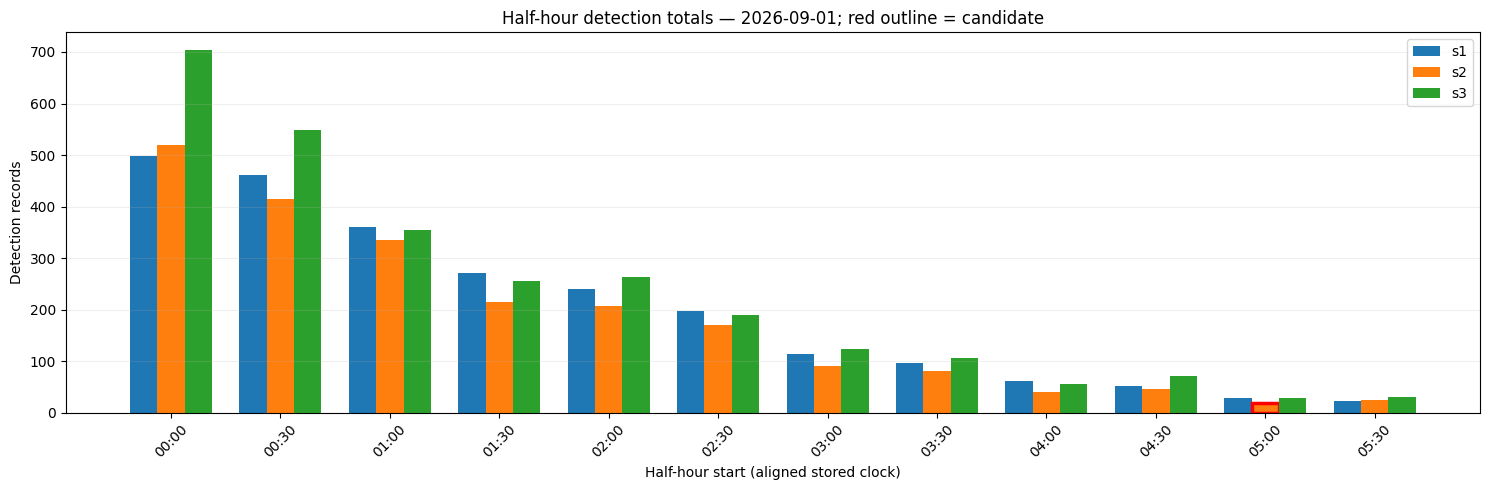

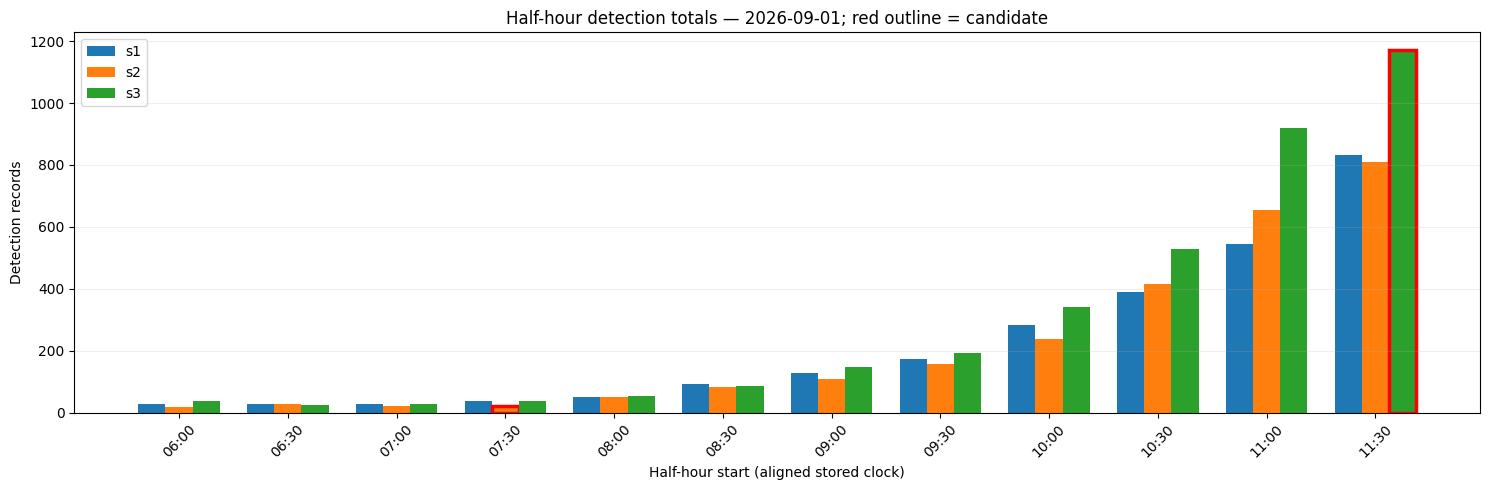

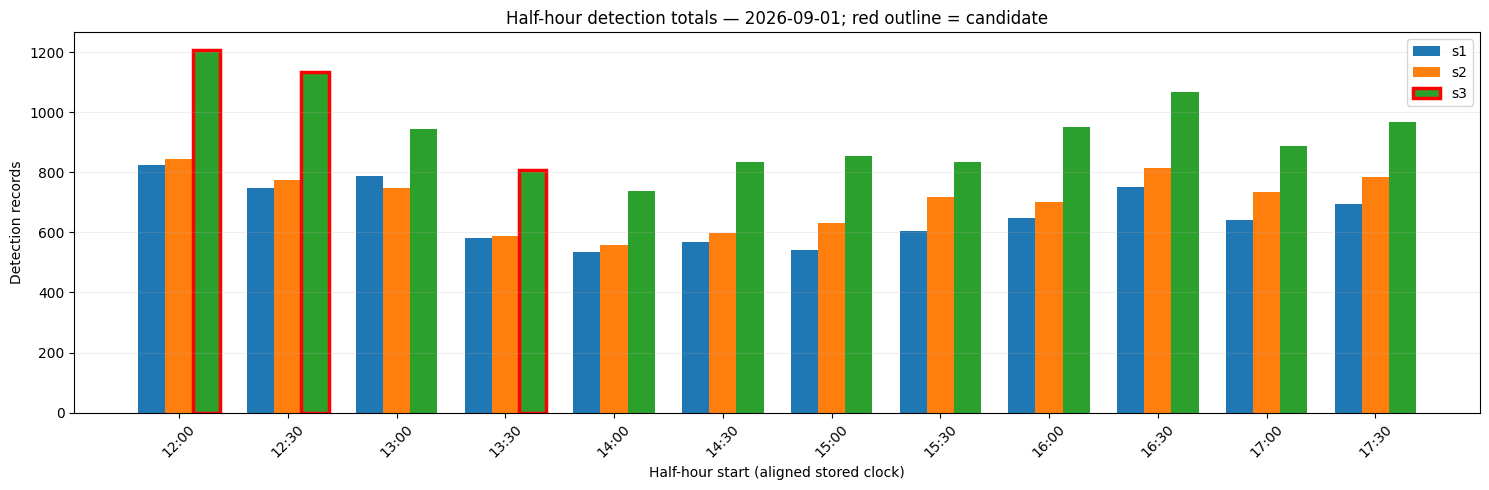

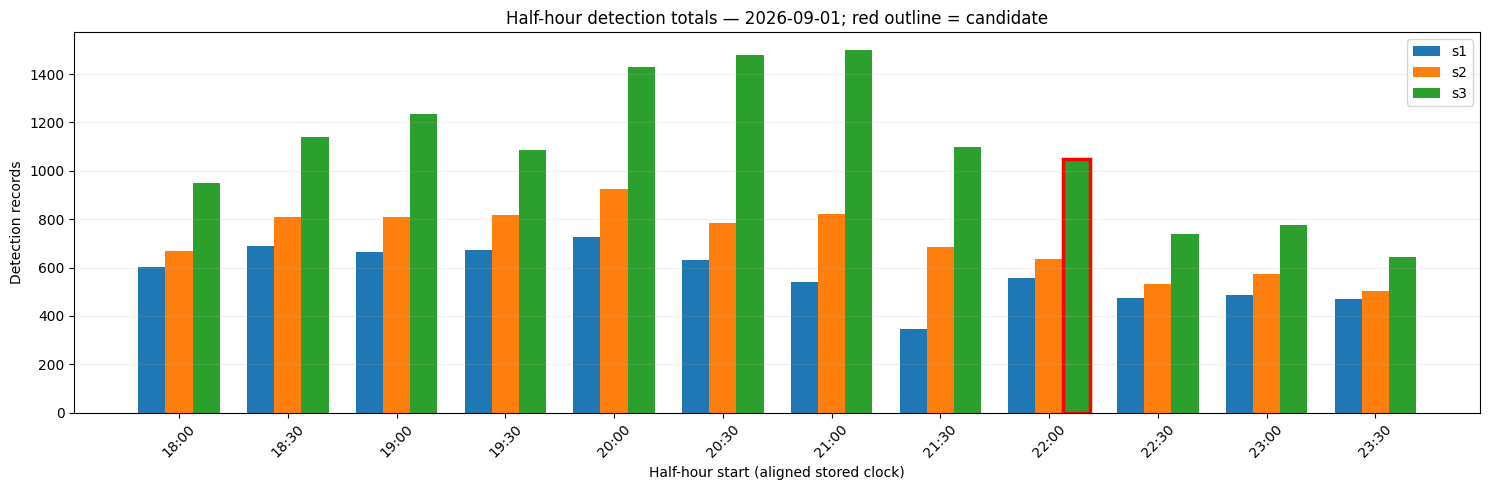

In [6]:
for offset in range(0, len(metrics), 12):
    page = metrics.iloc[offset:offset + 12]
    x = np.arange(len(page))
    fig, ax = plt.subplots(figsize=(15, 5))
    for index, sensor in enumerate(sensors):
        bars = ax.bar(x + (index - 1) * 0.25, page[f"{sensor}_total"], width=0.25,
                      color=colors[sensor], label=sensor)
        for bar, flag in zip(bars, page[f"{sensor}_flag"]):
            if flag:
                bar.set_edgecolor("red")
                bar.set_linewidth(2.5)
    ax.set_xticks(x, page["window_start"].dt.strftime("%H:%M"), rotation=45)
    ax.set_ylabel("Detection records")
    ax.set_xlabel("Half-hour start (aligned stored clock)")
    ax.set_title(f"Half-hour detection totals — {DAY}; red outline = candidate")
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    plt.show()

## Scores and flagged candidates

Each sensor is checked against the other two, using only half-hour totals. A flag requires both a high score and agreement between the references.

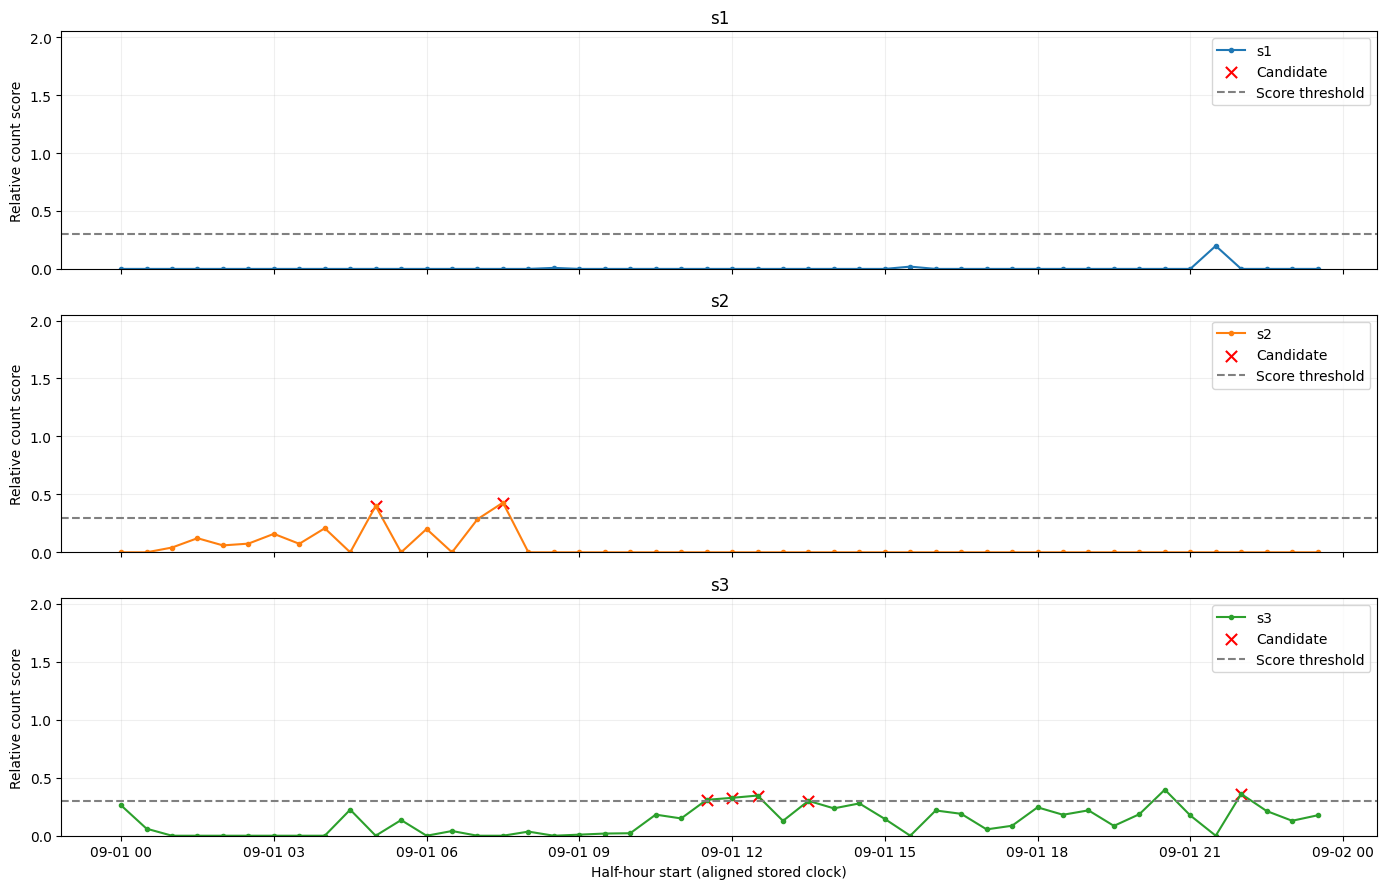

,window_start,window_end,sensor,coverage_minutes,total,reference_mean_total,count_difference,ratio_to_reference,reference_gap,score,flag
46,2026-09-01 07:30:00,2026-09-01 08:00:00,s2,30.0,22.0,37.0,-15.0,0.595,0.054,0.429,True
31,2026-09-01 05:00:00,2026-09-01 05:30:00,s2,30.0,18.0,28.5,-10.5,0.632,0.035,0.400,True
134,2026-09-01 22:00:00,2026-09-01 22:30:00,s3,30.0,1047.0,595.0,452.0,1.760,0.131,0.360,True
77,2026-09-01 12:30:00,2026-09-01 13:00:00,s3,30.0,1135.0,760.5,374.5,1.492,0.033,0.347,True
74,2026-09-01 12:00:00,2026-09-01 12:30:00,s3,30.0,1206.0,834.5,371.5,1.445,0.025,0.327,True
71,2026-09-01 11:30:00,2026-09-01 12:00:00,s3,30.0,1170.0,822.0,348.0,1.423,0.027,0.310,True
83,2026-09-01 13:30:00,2026-09-01 14:00:00,s3,30.0,809.0,585.0,224.0,1.383,0.014,0.301,True


In [7]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True, sharey=True)
for ax, sensor in zip(axes, sensors):
    ax.plot(metrics["window_start"], metrics[f"{sensor}_score"], color=colors[sensor], marker=".", label=sensor)
    flagged = metrics[metrics[f"{sensor}_flag"]]
    ax.scatter(flagged["window_start"], flagged[f"{sensor}_score"], color="red", marker="x", s=65, label="Candidate")
    ax.axhline(SCORE_THRESHOLD, color="gray", linestyle="--", label="Score threshold")
    ax.set_title(sensor)
    ax.set_ylabel("Relative count score")
    ax.set_ylim(0, 2.05)
    ax.grid(alpha=0.2)
    ax.legend()
axes[-1].set_xlabel("Half-hour start (aligned stored clock)")
plt.tight_layout()
plt.show()
with pd.option_context("display.max_rows", 144):
    display(sensor_metrics[sensor_metrics["flag"]].sort_values("score", ascending=False).round(3))

## Export the results

The window table has 48 rows; the sensor table has 144 rows. Boundary totals use 29.5 minutes of common coverage and are not extrapolated to 30 minutes.

In [8]:
output_dir = DATA_FILE.parent / "ai_hack_mobility_2026"
metrics.to_csv(output_dir / f"comparison_counts_windows_{DAY}_{COUNT_MODE}.csv", index=False)
sensor_metrics.to_csv(output_dir / f"comparison_counts_sensors_{DAY}_{COUNT_MODE}.csv", index=False)
print(f"Saved {len(metrics)} window rows and {len(sensor_metrics)} sensor/window rows.")

assert len(metrics) == 48 and len(sensor_metrics) == 144
assert metrics["coverage_minutes"].tolist() == [29.5] + [30.0] * 46 + [29.5]
for sensor in sensors:
    assert metrics[f"{sensor}_total"].sum() == aligned.dropna()[sensor].sum()
assert relative_gap(0, 0) == 0
assert relative_gap(0, 100) == 2
assert np.isclose(relative_gap(100, 120), 20 / 110)
assert score_and_flag(0, 0, 0) == (0, False)
for odd_sensor in sensors:
    totals = {s: 0 if s == odd_sensor else 100 for s in sensors}
    for sensor in sensors:
        a, b = [s for s in sensors if s != sensor]
        _, flag = score_and_flag(relative_gap(totals[sensor], totals[a]),
                                 relative_gap(totals[sensor], totals[b]), relative_gap(totals[a], totals[b]))
        assert flag == (sensor == odd_sensor)

Saved 48 window rows and 144 sensor/window rows.
